In [1]:
# Import Library
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency, f_oneway
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

import os
import pickle

import warnings
warnings.filterwarnings('ignore')

# Data Understanding

In [2]:
# Import Dataset
df = pd.read_csv('data/flight.csv')

print('Dataset flight')
print(f'Ukuran Dataset: {df.shape[0]} baris dan {df.shape[1]} kolom')
df.sample(5).T

Dataset flight
Ukuran Dataset: 62988 baris dan 23 kolom


,60364,17089,39475,11410,39512
MEMBER_NO,20662,58579,15659,56942,26454
FFP_DATE,7/27/2007,10/26/2010,5/23/2012,1/13/2008,11/14/2010
FIRST_FLIGHT_DATE,9/2/2013,1/15/2011,9/3/2012,5/7/2008,9/26/2011
GENDER,Male,Female,Male,Male,Male
FFP_TIER,4,4,4,4,4
WORK_CITY,shijiazhuang,guangzhou,shanghaishi,guangzhou,wulumuqi
WORK_PROVINCE,hebei,guangdong,shanghai,guangdong,xinjiang
WORK_COUNTRY,CN,CN,CN,CN,CN
AGE,37.0,41.0,29.0,56.0,44.0
LOAD_TIME,3/31/2014,3/31/2014,3/31/2014,3/31/2014,3/31/2014


In [3]:
# Identifikasi Tipe Data Masing-masing Kolom Dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 62988 entries, 0 to 62987
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   MEMBER_NO          62988 non-null  int64  
 1   FFP_DATE           62988 non-null  str    
 2   FIRST_FLIGHT_DATE  62988 non-null  str    
 3   GENDER             62985 non-null  str    
 4   FFP_TIER           62988 non-null  int64  
 5   WORK_CITY          60719 non-null  str    
 6   WORK_PROVINCE      59740 non-null  str    
 7   WORK_COUNTRY       62962 non-null  str    
 8   AGE                62568 non-null  float64
 9   LOAD_TIME          62988 non-null  str    
 10  FLIGHT_COUNT       62988 non-null  int64  
 11  BP_SUM             62988 non-null  int64  
 12  SUM_YR_1           62437 non-null  float64
 13  SUM_YR_2           62850 non-null  float64
 14  SEG_KM_SUM         62988 non-null  int64  
 15  LAST_FLIGHT_DATE   62988 non-null  str    
 16  LAST_TO_END        62988 non-null

Informasi Identitas

- MEMBER_NO-b: ID unik untuk setiap pelanggan
- GENDER: Jenis kelamin pelanggan
- AGE: Umur pelanggan
- WORK_CITY, WORK_PROVINCE, WORK_COUNTRY: Informasi tentang lokasi asal pelanggan

Informasi Penerbangan

- FIRST_FLIGHT_DATE: Tanggal penerbangan pertama pelanggan
- LAST_FLIGHT_DATE: Tanggal penerbangan terakhir pelanggan
- FLIGHT_COUNT: Jumlah penerbangan yang telah dilakukan pelanggan
- SEG_KM_SUM: Total jarak (km) penerbangan yang telah dilakukan pelanggan

Informasi Program Frequent Flyer

- FFP_DATE: Tanggal bergabung dengan program Frequent Flyer
- FFP_TIER: Tier pelanggan dalam program Frequent Flyer
- BP_SUM: Rencana perjalanan pelanggan
- SUM_YR_1, SUM_YR_2: Total kredit/point di tahun pertama dan kedua
- Points_Sum: Jumlah poin yang telah didapat pelanggan
- Point_NotFlight: Poin yang tidak digunakan oleh pelanggan

Informasi Lain

- LOAD_TIME: Tanggal data diambil
- AVG_INTERVAL: Rata-rata jarak waktu antara penerbangan
- MAX_INTERVAL: Maksimal jarak waktu antara penerbangan
- EXCHANGE_COUNT: Jumlah penukaran
- avg_discount: Rata-rata diskon yang didapat pelanggan

In [4]:
# Identifikasi Unique Value Masing-masing Feature Numerik
numerical_features = ['AGE', 'FLIGHT_COUNT', 'SEG_KM_SUM', 'BP_SUM', 'SUM_YR_1', 
                      'SUM_YR_2', 'Points_Sum', 'Point_NotFlight', 'AVG_INTERVAL', 'MAX_INTERVAL', 
                      'EXCHANGE_COUNT', 'avg_discount', 'LAST_TO_END']

for col in numerical_features:
  unique_count = df[col].nunique()
  print(f"{col}: {df[col].nunique()} unique values")
  print(f"Values: {df[col].unique()[:10]}")
  print("\n")

AGE: 84 unique values
Values: [31. 42. 40. 64. 48. 46. 50. 43. 34. 47.]


FLIGHT_COUNT: 153 unique values
Values: [210 140 135  23 152  92 101  73  56  64]


SEG_KM_SUM: 29081 unique values
Values: [580717 293678 283712 281336 309928 294585 287042 287230 321489 375074]


BP_SUM: 23449 unique values
Values: [505308 362480 351159 337314 273844 313338 248864 301864 262958 204855]


SUM_YR_1: 15828 unique values
Values: [239560. 171483. 163618. 116350. 124560. 112364. 120500.  82440.  72596.
  85258.]


SUM_YR_2: 16767 unique values
Values: [234188. 167434. 164982. 125500. 130702.  76946. 114469. 114971.  87401.
  60267.]


Points_Sum: 25062 unique values
Values: [619760 415768 406361 372204 338813 343121 298873 351198 295158 251907]


Point_NotFlight: 99 unique values
Values: [50 33 26 12 39 15 29 14  7 16]


AVG_INTERVAL: 10706 unique values
Values: [ 3.48325359  5.1942446   5.29850746 27.86363636  4.78807947  7.04395604
  7.19       10.11111111 13.05454545 11.33333333]


MAX_INTERVAL: 7

In [5]:
# Identifikasi Unique Value Masing-masing Feature Kategorikal
categorical_features = ['GENDER', 'WORK_CITY', 'WORK_PROVINCE', 'WORK_COUNTRY', 'FFP_TIER']

for col in categorical_features:
  unique_count = df[col].nunique()
  print(f"{col}: {df[col].nunique()} unique values")
  print(f"{df[col].value_counts()}")
  print("\n")

GENDER: 2 unique values
GENDER
Male      48134
Female    14851
Name: count, dtype: int64


WORK_CITY: 3234 unique values
WORK_CITY
guangzhou                  9386
beijing                    7845
shanghai                   5001
shenzhen                   3605
dalian                     1979
                           ... 
shandongshengqingdaoshi       1
GEELONG                       1
BELLREGUARD                   1
Danville                      1
lingshui                      1
Name: count, Length: 3234, dtype: int64


WORK_PROVINCE: 1165 unique values
WORK_PROVINCE
guangdong    17509
beijing       8014
shanghai      4998
liaoning      4182
xinjiang      2512
             ...  
ABIA             1
NYC              1
NOTARIO          1
TOPKPPI          1
JAWATIMUR        1
Name: count, Length: 1165, dtype: int64


WORK_COUNTRY: 118 unique values
WORK_COUNTRY
CN    57748
HK      991
JP      875
KR      790
US      575
      ...  
IA        1
cn        1
BG        1
CL        1
CR        1

In [6]:
# Identifikasi Unique Value Masing-masing Feature Tanggal
date_features = ["FIRST_FLIGHT_DATE", "LAST_FLIGHT_DATE", "FFP_DATE", "LOAD_TIME"]

for col in date_features:
  unique_count = df[col].nunique()
  print(f"{col}: {df[col].nunique()} unique values")
  print(f"Values: {df[col].unique()[:10]}")
  print("\n")

FIRST_FLIGHT_DATE: 3406 unique values
Values: <ArrowStringArray>
['12/24/2008',   '8/3/2007',  '8/30/2007',  '8/23/2008',  '4/15/2009',
  '9/29/2009',  '3/29/2006',   '4/9/2010',   '7/1/2011',   '7/5/2010']
Length: 10, dtype: str


LAST_FLIGHT_DATE: 731 unique values
Values: <ArrowStringArray>
[ '3/31/2014',  '3/25/2014',  '3/21/2014', '12/26/2013',  '3/27/2014',
  '1/13/2014',  '3/29/2014',  '3/26/2014',  '3/17/2014',  '3/10/2014']
Length: 10, dtype: str


FFP_DATE: 3068 unique values
Values: <ArrowStringArray>
['11/2/2006', '2/19/2007',  '2/1/2007', '8/22/2008', '4/10/2009', '2/10/2008',
 '3/22/2006',  '4/9/2010',  '6/7/2011',  '7/5/2010']
Length: 10, dtype: str


LOAD_TIME: 1 unique values
Values: <ArrowStringArray>
['3/31/2014']
Length: 1, dtype: str




# Data Cleaning

In [8]:
# Identifikasi Duplicate Row
print(f"\n Jumlah Duplicate Row: {df.duplicated().sum()}")

if df.duplicated().sum() > 0:
  print("\nDuplicate Row:")
  duplicates = df[df.duplicated(keep=False)]
  print(duplicates.sort_values('MEMBER_NO'))


 Jumlah Duplicate Row: 0


In [9]:
# Membuat Salinan Dataframe Pada Tahap Data Cleaning
df_cleaned = df.copy()

In [10]:
# Memperbaiki Tipe Data Feature Tanggal
date_features = ["FIRST_FLIGHT_DATE", "LAST_FLIGHT_DATE", "FFP_DATE", "LOAD_TIME"]

for col in date_features:
  df_cleaned[col] = pd.to_datetime(df_cleaned[col], errors="coerce")
  print(f"{col}: {df_cleaned[col].dtype}")

FIRST_FLIGHT_DATE: datetime64[us]
LAST_FLIGHT_DATE: datetime64[us]
FFP_DATE: datetime64[us]
LOAD_TIME: datetime64[us]


# Exploratory Data Analysis

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


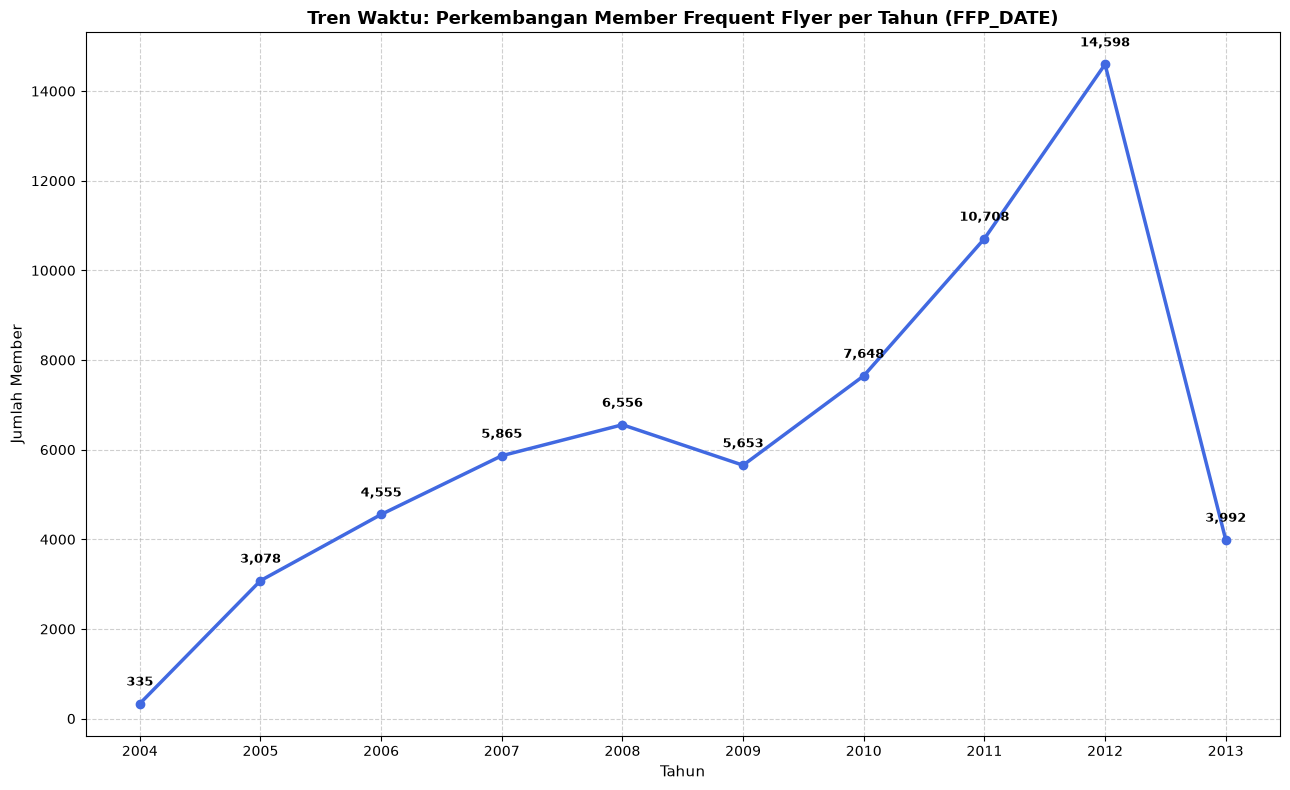

In [11]:
# Identifikasi Tren Waktu Berdasarkan Feature "FFP DATE"
ffp_trend = df_cleaned['FFP_DATE'].dt.year.value_counts().sort_index()

plt.figure(figsize=(13, 8))
plt.plot(
    ffp_trend.index.astype(str),
    ffp_trend.values,
    marker='o',
    color='royalblue',
    linewidth=2.5,
    markersize=6,
)

plt.title(
    'Tren Waktu: Perkembangan Member Frequent Flyer per Tahun (FFP_DATE)',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Tahun', fontsize=11)
plt.ylabel('Jumlah Member', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

for x, y in zip(ffp_trend.index.astype(str), ffp_trend.values):
  plt.text(x, y + 400, f'{y:,}', ha='center', fontsize=9, fontweight='semibold')

plt.tight_layout()
plt.show()

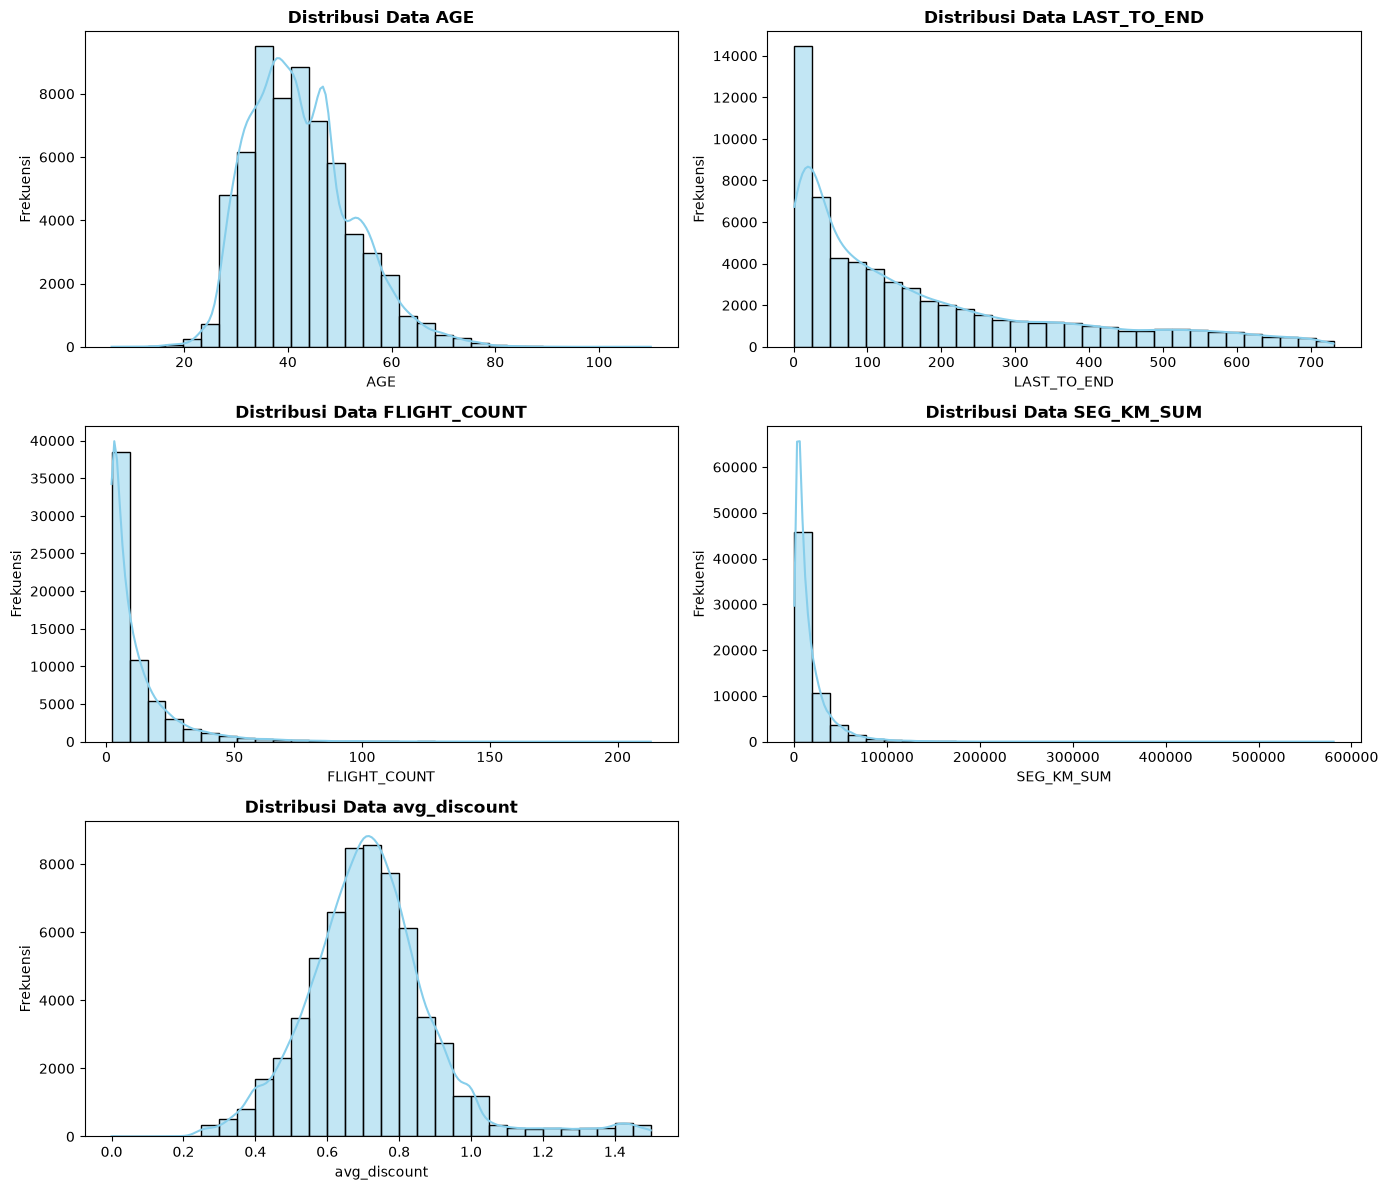

In [12]:
# Identifikasi Distribusi Feature "AGE", "LAST_TO_END", "FLIGHT_COUNT", "SEG_KM_SUM", "avg_discount"
distribution_data = ['AGE', 'LAST_TO_END', 'FLIGHT_COUNT', 'SEG_KM_SUM', 'avg_discount']
n_cols = 2
n_rows = (len(distribution_data) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(distribution_data):
    sns.histplot(data=df_cleaned, x=col, ax=axes[i], color='skyblue', kde=True, bins=30)
    axes[i].set_title(f'Distribusi Data {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

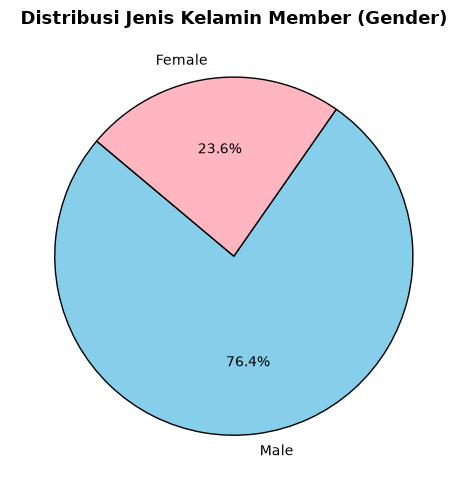

In [13]:
# Identifikasi Distribusi Feature "Gender"
gender_counts = df_cleaned['GENDER'].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['skyblue', 'lightpink'],
    wedgeprops={'edgecolor': 'black', 'linewidth': 1},
)

plt.title(
    'Distribusi Jenis Kelamin Member (Gender)', fontsize=13, fontweight='bold'
)
plt.tight_layout()
plt.show()

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


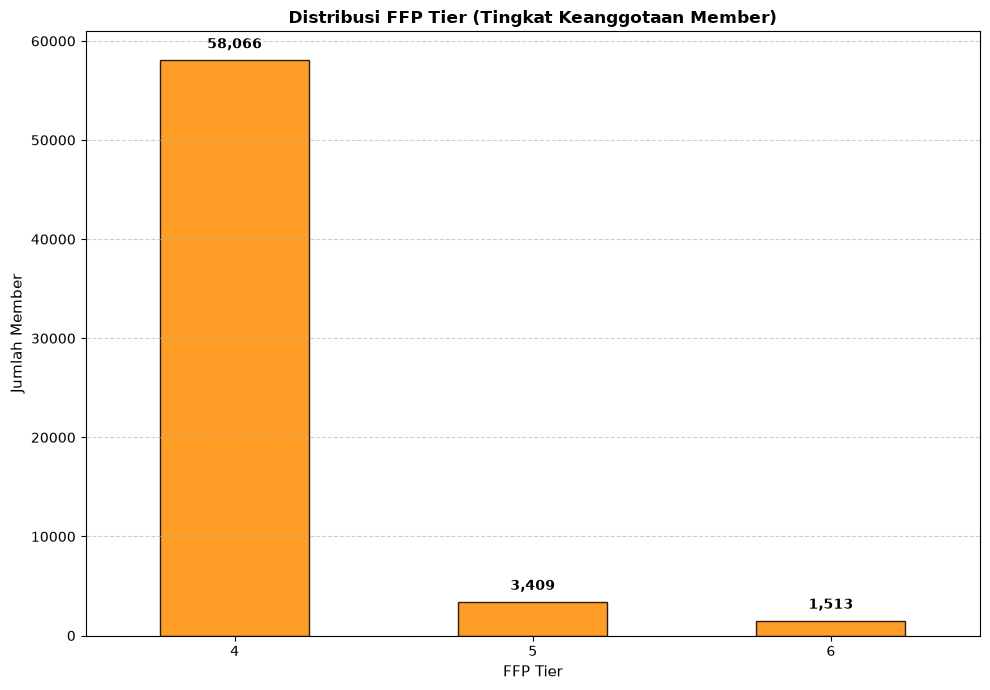

In [14]:
# Identifikasi Distribusi Feature "FPP_TIER"
tier_counts = df_cleaned["FFP_TIER"].value_counts().sort_index()

plt.figure(figsize=(10, 7))
ax = tier_counts.plot(
    kind="bar", color="darkorange", edgecolor="black", alpha=0.85
)
plt.title(
    "Distribusi FFP Tier (Tingkat Keanggotaan Member)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("FFP Tier", fontsize=11)
plt.ylabel("Jumlah Member", fontsize=11)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.6)

for i, v in enumerate(tier_counts):
  ax.text(i, v + 1200, f"{v:,}", ha="center", fontsize=10, fontweight="semibold")

plt.tight_layout()
plt.show()

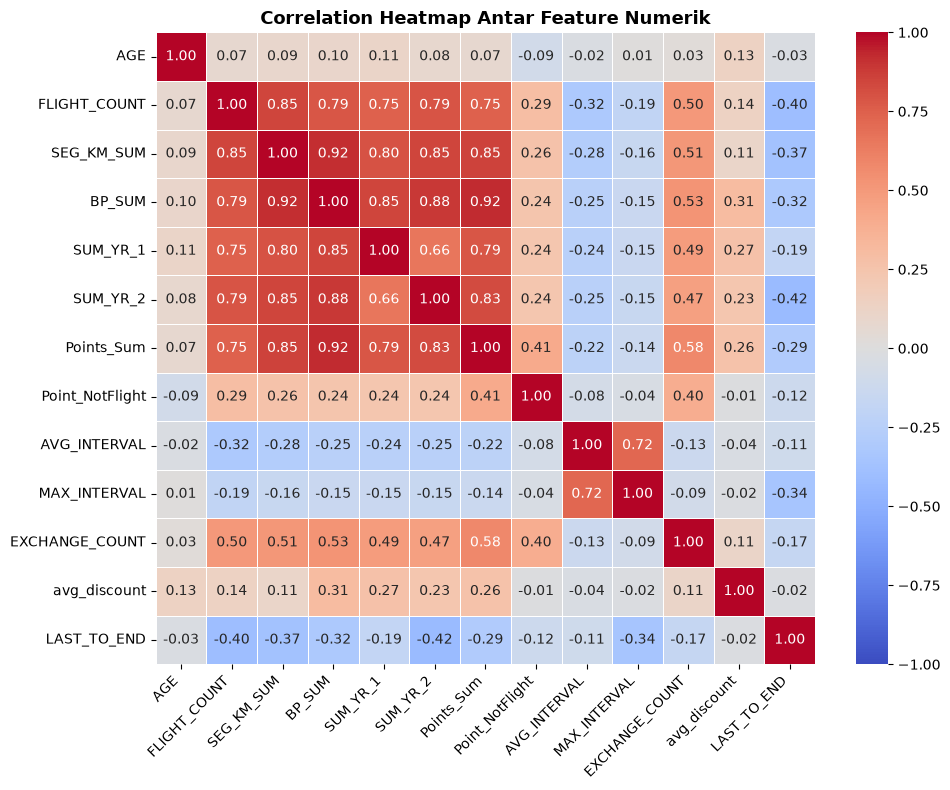

In [15]:
# Identifikasi Korelasi Antar Feature Numerik
corr_matrix = df_cleaned[numerical_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,  
    cmap='coolwarm',  
    fmt='.2f',  
    linewidths=0.5,  
    vmin=-1,
    vmax=1,  
    cbar=True,
)

plt.title(
    'Correlation Heatmap Antar Feature Numerik',
    fontsize=13,
    fontweight='bold',
)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Data Preprocessing

In [16]:
# Identifikasi Missing Value
print("\n Jumlah Missing Values:")
missing_count = df_cleaned.isnull().sum()
print(missing_count[missing_count > 0])

print("\n Persentase Missing Values:")
missing_pct = (df_cleaned.isnull().sum() / len(df_cleaned) * 100).round(3)
missing_summary = pd.DataFrame({
    'Jumlah': missing_count,
    'Persentase (%)': missing_pct
})
print(missing_summary[missing_summary['Jumlah'] > 0].sort_values('Persentase (%)', ascending=False))


 Jumlah Missing Values:
GENDER                 3
WORK_CITY           2269
WORK_PROVINCE       3248
WORK_COUNTRY          26
AGE                  420
SUM_YR_1             551
SUM_YR_2             138
LAST_FLIGHT_DATE     421
dtype: int64

 Persentase Missing Values:
                  Jumlah  Persentase (%)
WORK_PROVINCE       3248           5.157
WORK_CITY           2269           3.602
SUM_YR_1             551           0.875
LAST_FLIGHT_DATE     421           0.668
AGE                  420           0.667
SUM_YR_2             138           0.219
WORK_COUNTRY          26           0.041
GENDER                 3           0.005


In [17]:
# Identifikasi Penanganan Missing Value
threshold = 20  # 20% threshold

for col in df_cleaned.columns:
    missing_pct = (df_cleaned[col].isnull().sum() / len(df_cleaned)) * 100

    if missing_pct > threshold:
        print(f"\n Hapus {col}: {missing_pct:.3f}% missing (> {threshold}%)")
    elif missing_pct > 0:
        if df_cleaned[col].dtype in ['int64', 'float64']:
            print(f"\n Isi {col}: {missing_pct:.3f}% missing - Gunakan MEDIAN")
        else:
            print(f"\n Isi {col}: {missing_pct:.3f}% missing - Gunakan MODE")


 Isi GENDER: 0.005% missing - Gunakan MODE

 Isi WORK_CITY: 3.602% missing - Gunakan MODE

 Isi WORK_PROVINCE: 5.157% missing - Gunakan MODE

 Isi WORK_COUNTRY: 0.041% missing - Gunakan MODE

 Isi AGE: 0.667% missing - Gunakan MEDIAN

 Isi SUM_YR_1: 0.875% missing - Gunakan MEDIAN

 Isi SUM_YR_2: 0.219% missing - Gunakan MEDIAN

 Isi LAST_FLIGHT_DATE: 0.668% missing - Gunakan MODE


In [19]:
# Membuat Salinan Dataframe Pada Tahap Data Preprocessing
df_ready = df_cleaned.copy()

In [20]:
# Penanganan Missing Value Feature Numerik
missing_numerical = ['AGE', 'SUM_YR_1', 'SUM_YR_2']

print("\n Feature Numerik:")
for col in missing_numerical:
    if df_cleaned[col].isnull().sum() > 0:
        median_value = df_cleaned[col].median()
        df_ready[col] = df_ready[col].fillna(median_value)
        print(f' Missing value feature "{col}" diisi dengan median = {median_value:.2f}') 


 Feature Numerik:
 Missing value feature "AGE" diisi dengan median = 41.00
 Missing value feature "SUM_YR_1" diisi dengan median = 2800.00
 Missing value feature "SUM_YR_2" diisi dengan median = 2773.00


In [21]:
# Penanganan Missing Value Feature Kategorikal
missing_categorical = ['GENDER', 'WORK_CITY', 'WORK_PROVINCE', 'WORK_COUNTRY', 'LAST_FLIGHT_DATE']

print("\n Feature Kategorikal:")
for col in missing_categorical:
    if df_cleaned[col].isnull().sum() > 0:
        mode_value = df_cleaned[col].mode()[0]
        df_ready[col] = df_ready[col].fillna(mode_value)
        print(f' Missing value feature "{col}" diisi dengan modus = "{mode_value}"')


 Feature Kategorikal:
 Missing value feature "GENDER" diisi dengan modus = "Male"
 Missing value feature "WORK_CITY" diisi dengan modus = "guangzhou"
 Missing value feature "WORK_PROVINCE" diisi dengan modus = "guangdong"
 Missing value feature "WORK_COUNTRY" diisi dengan modus = "CN"
 Missing value feature "LAST_FLIGHT_DATE" diisi dengan modus = "2014-03-31 00:00:00"


In [22]:
print("\n Sisa missing value setelah penanganan missing value:")
print(df_ready.isnull().sum().sum())


 Sisa missing value setelah penanganan missing value:
0


In [23]:
# Membuat Feature "Length"
df_ready['Length'] = (df_ready['LOAD_TIME'] - df_ready['FFP_DATE']).dt.days

# Membuat Feature "Frequency"
flight_duration_days = (df_ready['LAST_FLIGHT_DATE'] - df_ready['FIRST_FLIGHT_DATE']).dt.days
flight_duration_years = np.maximum(flight_duration_days, 1) / 365.25
df_ready['Frequency'] = df_ready['FLIGHT_COUNT'] / flight_duration_years

# Menentukan Feature-feature untuk Pembuatan Kluster
features = ['Length', 'LAST_TO_END', 'Frequency', 'SEG_KM_SUM', 'avg_discount', 'FFP_TIER']
df_cluster = df_ready[features].copy()
df_cluster = df_cluster.rename(
              columns={'LAST_TO_END': 'Recency', 'SEG_KM_SUM': 'Mileage', 'avg_discount': 'Coefficient'}
)
print("Feature-feature untuk Pembuatan Kluster:")
df_cluster.sample(10)

Feature-feature untuk Pembuatan Kluster:


,Length,Recency,Frequency,Mileage,Coefficient,FFP_TIER
17828,690,16,6.852720,13277,1.032934,5
27687,2002,375,2.244929,10535,0.791324,4
49172,1031,578,4.013736,6232,0.463495,4
46595,2492,316,0.503330,5042,0.662108,4
25766,534,125,33.976744,11368,0.807500,4
50205,2494,25,0.302986,3774,0.721214,4
50063,1076,29,1.394084,4557,0.602620,4
4809,2471,103,2.493174,52026,0.669869,4
53046,705,704,365.250000,2710,0.850000,4
18607,1657,59,4.109063,24067,0.546866,4


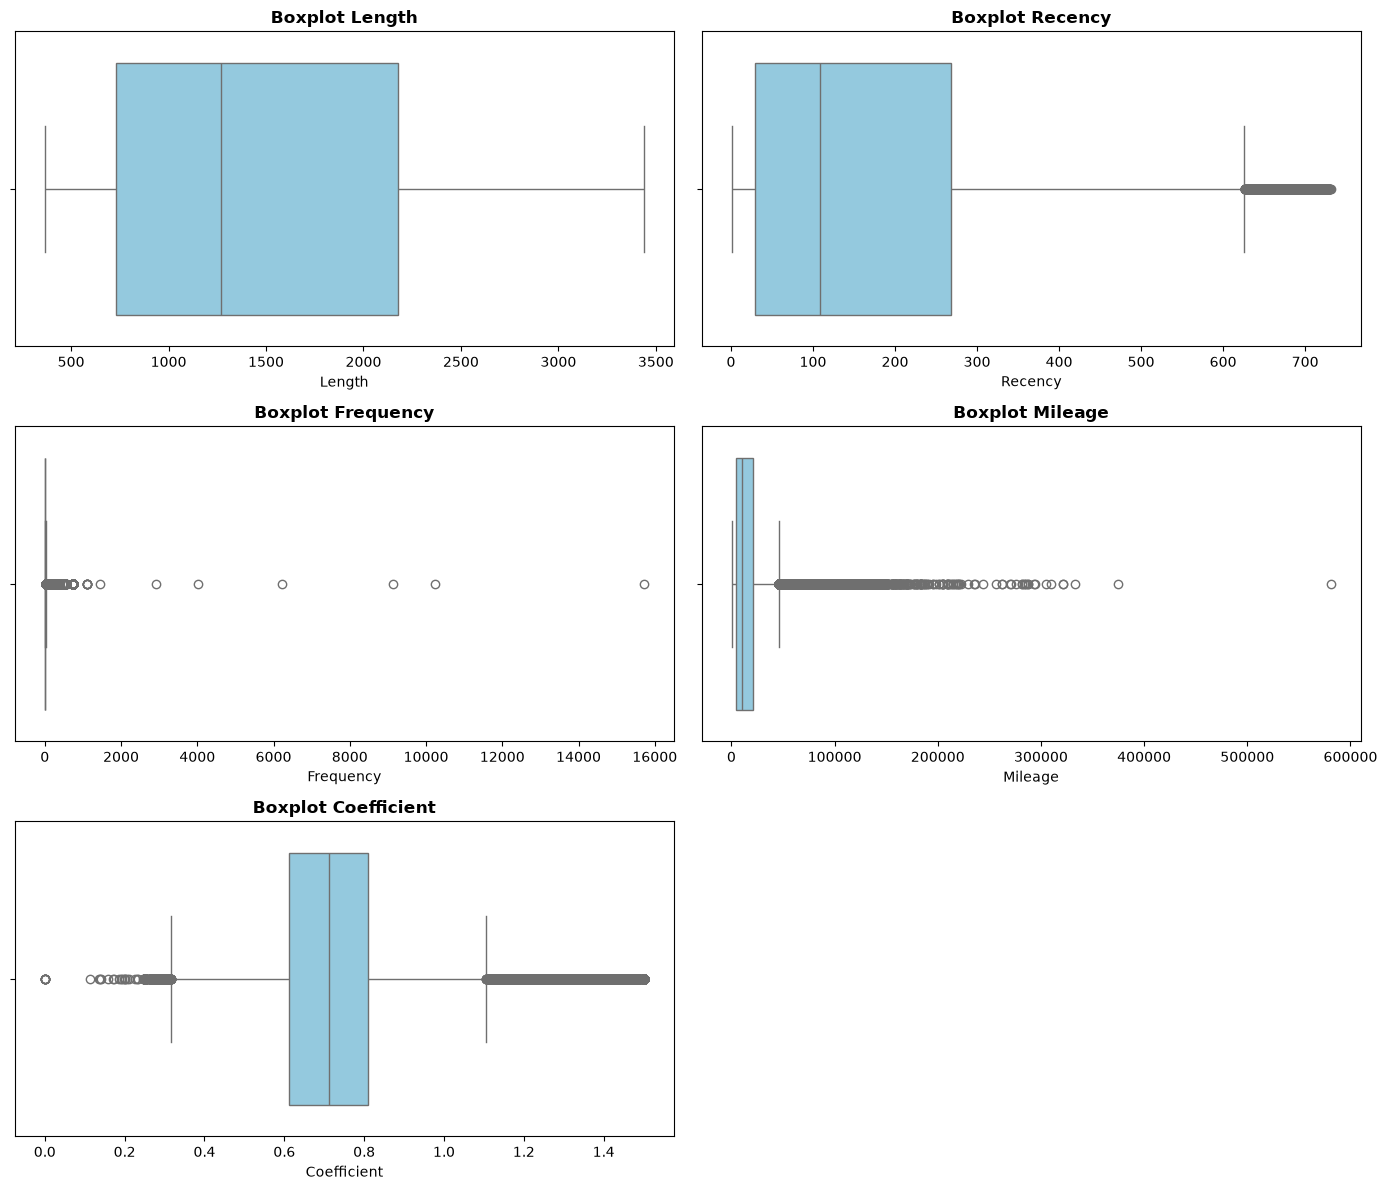

In [24]:
# Identifikasi Outlier Pada Feature Numerik untuk Pembuatan Kluster
numerical_cluster = ['Length', 'Recency', 'Frequency', 'Mileage', 'Coefficient']
n_cols = 2
n_rows = (len(numerical_cluster) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(numerical_cluster):
    sns.boxplot(data=df_cluster, x=col, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Boxplot {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel(col)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [25]:
# Menghitung Outlier Pada Feature Numerik untuk Pembuatan Kluster
total_outlier_rows = (
    set()
)

print("--- Detail Outlier per Kolom ---")
for col in numerical_cluster:
  Q1 = df_cluster[col].quantile(0.25)
  Q3 = df_cluster[col].quantile(0.75)
  IQR = Q3 - Q1
  batas_bawah = Q1 - 1.5 * IQR
  batas_atas = Q3 + 1.5 * IQR

  outlier_indices = df_cluster[
      (df_cluster[col] < batas_bawah) | (df_cluster[col] > batas_atas)
  ].index
  total_outlier_rows.update(
      outlier_indices
  )

  outlier = df_cluster.loc[outlier_indices]
  print(f"Kolom: {col}, Jumlah Outlier: {len(outlier)}")

# Menghitung total keseluruhan dan persentase
jumlah_total_outlier = len(total_outlier_rows)
persentase_outlier = (jumlah_total_outlier / len(df_cluster)) * 100

print("\n----------------------------------------")
print(f"Total Baris Unik yang Mengandung Outlier: {jumlah_total_outlier}")
print(f"Persentase dari Total Outlier Feature Numerik untuk Pembuatan Kluster: {persentase_outlier:.2f}%")

--- Detail Outlier per Kolom ---
Kolom: Length, Jumlah Outlier: 0
Kolom: Recency, Jumlah Outlier: 1835
Kolom: Frequency, Jumlah Outlier: 6260
Kolom: Mileage, Jumlah Outlier: 4792
Kolom: Coefficient, Jumlah Outlier: 2573

----------------------------------------
Total Baris Unik yang Mengandung Outlier: 13330
Persentase dari Total Outlier Feature Numerik untuk Pembuatan Kluster: 21.16%


In [26]:
# Identifikasi Statistik Deskriptif Feature "LRFMC"
lrfmc_features = df_cluster.drop(columns=['FFP_TIER'])
lrfmc_features.describe().round(3)

,Length,Recency,Frequency,Mileage,Coefficient
count,62988.000,62988.000,62988.000,62988.000,62988.000
mean,1485.001,176.120,20.607,17123.879,0.722
std,847.223,183.822,119.264,20960.845,0.185
min,365.000,1.000,0.074,368.000,0.000
25%,732.000,29.000,1.663,4747.000,0.612
50%,1270.000,108.000,3.927,9994.000,0.712
75%,2179.000,268.000,8.696,21271.250,0.809
max,3437.000,731.000,15705.750,580717.000,1.500


In [27]:
# Melakukan Transformasi Logaritma Pada Feature "LRFMC" yang Sangat Skewed
df_log = df_cluster.copy()

skewed_cols = ['Frequency', 'Mileage', 'Recency']
for col in skewed_cols:
  df_log[col] = np.log1p(df_log[col])

print('Berhasil melakukan transformasi logaritma pada feature "LRFMC" yang sangat skewed!')

Berhasil melakukan transformasi logaritma pada feature "LRFMC" yang sangat skewed!


In [28]:
# Melakukan Scaling Feature-feature untuk Pembuatan Kluster
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_log)
print('Berhasil melakukan scaling feature-feature untuk pembuatan kluster!')

Berhasil melakukan scaling feature-feature untuk pembuatan kluster!


# Clustering

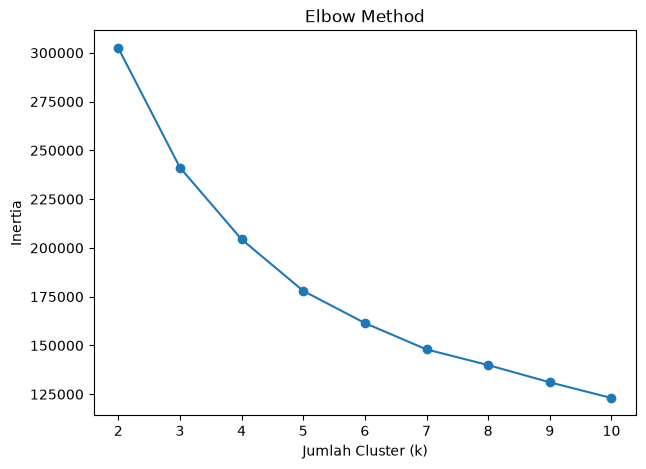

In [29]:
# Menentukan K Kluster Berdasarkan Elbow Method
inertia = []
K = range(2, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_data)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(7,5))
plt.plot(K, inertia, marker='o')
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

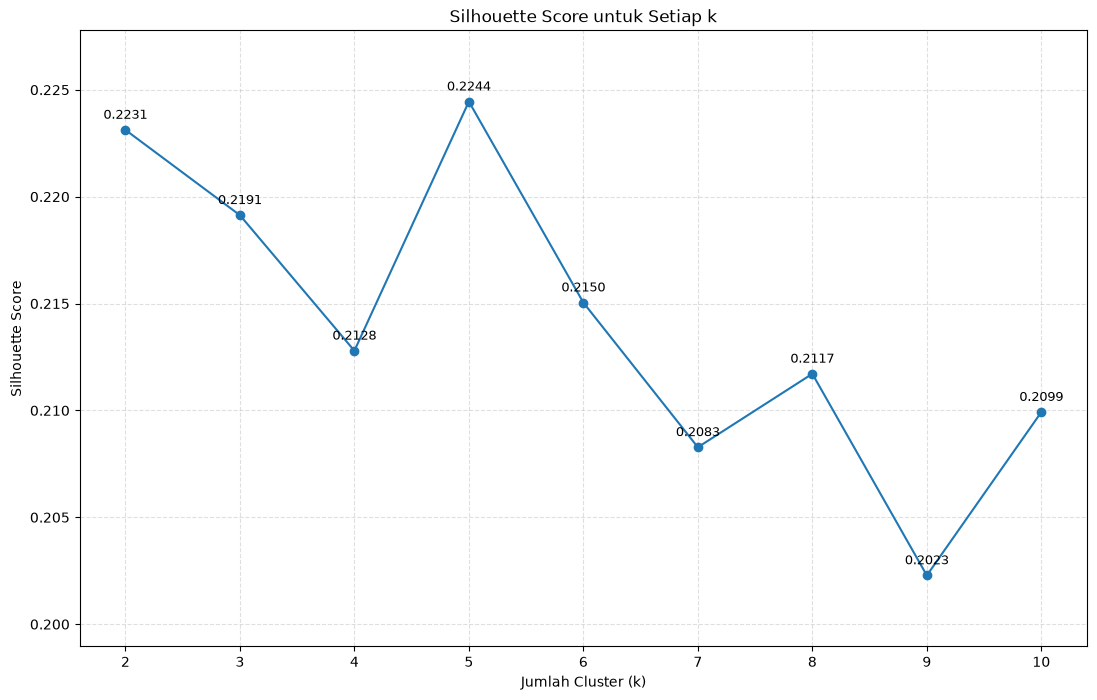

In [36]:
# Identifikasi Silhouette Score untuk Masing-masing K Kluster
silhouette_scores = []

for k in K:
  kmeans = KMeans(n_clusters=k, random_state=42)
  labels = kmeans.fit_predict(scaled_data)
  score = silhouette_score(scaled_data, labels)
  silhouette_scores.append(score)

plt.figure(figsize=(13, 8))
plt.plot(K, silhouette_scores, marker="o")

for k_val, score in zip(K, silhouette_scores):
  plt.annotate(
      f"{score:.4f}",
      (k_val, score),
      textcoords="offset points",
      xytext=(0, 8),
      ha="center",
      fontsize=9,
  )

plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score untuk Setiap k")
plt.margins(y=0.15)  
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()

In [30]:
# Membuat Kluster Sebanyak 5 Kluster
optimal_k = 5
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
df_cluster['Cluster'] = kmeans.fit_predict(scaled_data)

df_cluster.head()

,Length,Recency,Frequency,Mileage,Coefficient,FFP_TIER,Cluster
0,2706,1,39.886895,580717,0.961639,6,2
1,2597,7,21.077906,293678,1.252314,6,2
2,2615,11,20.588205,283712,1.254676,6,2
3,2047,97,4.305869,281336,1.090870,5,2
4,1816,5,30.723852,309928,0.970658,6,2


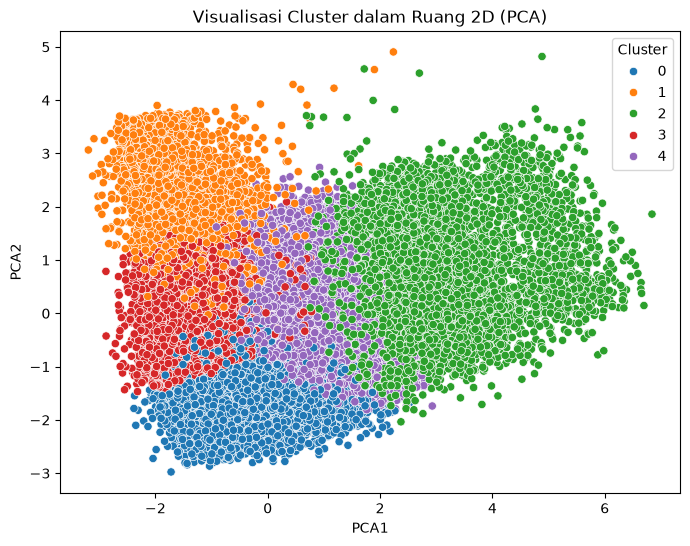

In [31]:
# Membuat Visualisasi Hasil Pembuatan 5 Kluster
pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_data)

df_cluster['PCA1'] = pca_result[:, 0]
df_cluster['PCA2'] = pca_result[:, 1]

plt.figure(figsize=(8,6))
sns.scatterplot(data=df_cluster, x="PCA1", y="PCA2", hue="Cluster", palette="tab10")
plt.title("Visualisasi Cluster dalam Ruang 2D (PCA)")
plt.show()

# Cluster Insight

In [32]:
# Membuat Salinan Dataframe Pada Tahap Cluster Insight
df_prof = df_cluster.copy()

In [33]:
# Menentukan Feature-feature Diluar "df_cluster" untuk Cluster Insight
extra_cols_from_ready = [
    "GENDER",
    "SUM_YR_1",
    "SUM_YR_2",
    "AVG_INTERVAL",
]
for col in extra_cols_from_ready:
  if col in df_ready.columns:
    df_prof[col] = df_ready.loc[df_prof.index, col]

# Menetapkan Feature "FPP_TIER" dan "GENDER" Sebagai Feature Kategorikal
cat_cols = ["FFP_TIER", "GENDER"]
for col in cat_cols:
  if col in df_prof.columns:
    df_prof[col] = df_prof[col].astype(str)

# Menentukan Feature Numerik untuk Cluster Insight
num_cols = [
    c
    for c in [
        "Length",
        "Recency",
        "Frequency",
        "Mileage",
        "Coefficient",
        "SUM_YR_1",
        "SUM_YR_2",
        "AVG_INTERVAL",
    ]
    if c in df_prof.columns
]

In [34]:
# Ukuran & Persentase Masing-masing Klaster
cluster_summary = pd.DataFrame({
    "jumlah_pelanggan": df_prof["Cluster"].value_counts().sort_index(),
    "persentase (%)": (
        df_prof["Cluster"].value_counts(normalize=True).sort_index() * 100
    ).round(2),
})

# Rata-rata (Mean) untuk Feature Numerik
mean_profile = df_prof.groupby("Cluster")[num_cols].mean().round(2)

print("=== RINGKASAN UKURAN KLASTER ===")
print(cluster_summary)

print("\n=== MEAN PROFIL NUMERIK ===")
print(mean_profile)

=== RINGKASAN UKURAN KLASTER ===
         jumlah_pelanggan  persentase (%)
Cluster                                  
0                   16324           25.92
1                    3913            6.21
2                    4841            7.69
3                   21439           34.04
4                   16471           26.15

=== MEAN PROFIL NUMERIK ===
          Length  Recency  Frequency   Mileage  Coefficient  SUM_YR_1  \
Cluster                                                                 
0        2449.78   198.82       1.69  10980.27         0.73   3657.01   
1         801.02   418.82     242.78   4367.62         0.67   1794.71   
2        1837.39    31.71      15.44  55848.03         0.87  18044.35   
3         902.10   254.14       5.73   7736.00         0.70   2796.61   
4        1346.47    36.86       7.45  27081.18         0.71   7400.12   

         SUM_YR_2  AVG_INTERVAL  
Cluster                          
0         3102.70         82.28  
1          766.26          6.9

In [35]:
# Distribusi Persentase Feature Kategorikal Per Klaster
for col in cat_cols:
  if col in df_prof.columns:
    print(f"\n=== DISTRIBUSI {col} (% per Cluster) ===")
    ct = pd.crosstab(df_prof["Cluster"], df_prof[col], normalize="index") * 100
    print(ct.round(2))


=== DISTRIBUSI FFP_TIER (% per Cluster) ===
FFP_TIER       4      5      6
Cluster                       
0          99.81   0.19   0.00
1          99.85   0.13   0.03
2           0.00  68.77  31.23
3          99.79   0.21   0.00
4         100.00   0.00   0.00

=== DISTRIBUSI GENDER (% per Cluster) ===
GENDER   Female   Male
Cluster               
0         20.93  79.07
1         34.32  65.68
2         13.01  86.99
3         27.92  72.08
4         21.11  78.89


# Export

In [36]:
# Membuat Dictionary dari Hasil Cluster Insight
profiling_data = {
    "cluster_summary": cluster_summary,
    "mean_profile": mean_profile,
    "crosstab_ffp_tier": (
        pd.crosstab(df_prof["Cluster"], df_prof["FFP_TIER"], normalize="index")
        * 100
    ).round(2),
    "crosstab_gender": (
        pd.crosstab(df_prof["Cluster"], df_prof["GENDER"], normalize="index")
        * 100
    ).round(2),
}

# Export Hasil Scaling Data, Model K-Means, dan Cluster Insight ke Folder "pickle/""
with open("pickle/scaler.pkl", "wb") as f:
  pickle.dump(scaler, f)

with open("pickle/kmeans_model.pkl", "wb") as f:
  pickle.dump(kmeans, f)

with open("pickle/profiling_data.pkl", "wb") as f:
  pickle.dump(profiling_data, f)

print(
    "Berhasil menyimpan scaler.pkl, kmeans_model.pkl, dan profiling_data.pkl ke"
    " folder pickle/"
)

Berhasil menyimpan scaler.pkl, kmeans_model.pkl, dan profiling_data.pkl ke folder pickle/
